# ECG beat classification: SVM vs Random Forest, beat vs patient hold-out

This notebook covers requirements 1–3 of the assessed exercise:

1. Load and inspect the data, plot examples of each arrhythmia type, one-hot encode the labels.
2. Classify beats with the **beat hold-out** split (random 75/25 split of all beats).
3. Classify beats with the **patient hold-out** split (records 104, 113, 119, 208, 210 are only used for testing).

Two classifiers are compared on both splits:

| Model | Main idea | Parameters tuned |
|---|---|---|
| **SVM** (RBF kernel) | Finds the boundary between classes with the widest possible margin. The RBF kernel lets that boundary curve, by comparing each beat with stored "support" beats. | `C` – how strongly misclassified training beats are punished (higher = tighter fit, more risk of overfitting). `gamma='scale'` – width of the RBF similarity. |
| **Random Forest** | Many decision trees, each trained on a random bootstrap sample and random subsets of the 275 time points; the forest takes a majority vote. | `n_estimators` (number of trees), `max_features` (time points considered at each split), `min_samples_leaf`. |

Run `data_preprocess.ipynb` and `data_split_resample.ipynb` first – they create the CSV files in `data/`.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from ecg_utils import load_split, one_hot, evaluate, CLASS_IDS, CLASS_NAMES, DATA_DIR, FIG_DIR

SEED = 42  # fixed seed -> results are reproducible
FIG_DIR.mkdir(exist_ok=True)

## 1. Load and inspect the data

In [2]:
Xb_train, yb_train, Xb_test, yb_test = load_split("beats")
Xp_train, yp_train, Xp_test, yp_test = load_split("patients")

for name, X, y in [("Beat hold-out    train", Xb_train, yb_train), ("Beat hold-out    test ", Xb_test, yb_test),
                   ("Patient hold-out train", Xp_train, yp_train), ("Patient hold-out test ", Xp_test, yp_test)]:
    counts = {CLASS_NAMES[c - 1]: int((y == c).sum()) for c in CLASS_IDS}
    print(f"{name}: X {X.shape}  per class {counts}")

Beat hold-out    train: X (30992, 275)  per class {'N': 3874, 'L': 3874, 'R': 3874, 'V': 3874, 'A': 3874, 'F': 3874, 'f': 3874, '/': 3874}
Beat hold-out    test : X (37442, 275)  per class {'N': 28474, 'L': 1636, 'R': 2581, 'V': 1307, 'A': 783, 'F': 191, 'f': 416, '/': 2054}
Patient hold-out train: X (35384, 275)  per class {'N': 4423, 'L': 4423, 'R': 4423, 'V': 4423, 'A': 4423, 'F': 4423, 'f': 4423, '/': 4423}
Patient hold-out test : X (14482, 275)  per class {'N': 9363, 'L': 0, 'R': 0, 'V': 1087, 'A': 0, 'F': 387, 'f': 1138, '/': 2507}


The training sets are balanced (every class has the same number of beats after re-sampling), the test sets are not –
they keep the real class distribution, which is what the model would meet in practice. The patient hold-out test set
contains **no L, R or A beats**, because none of the five held-out patients has them.

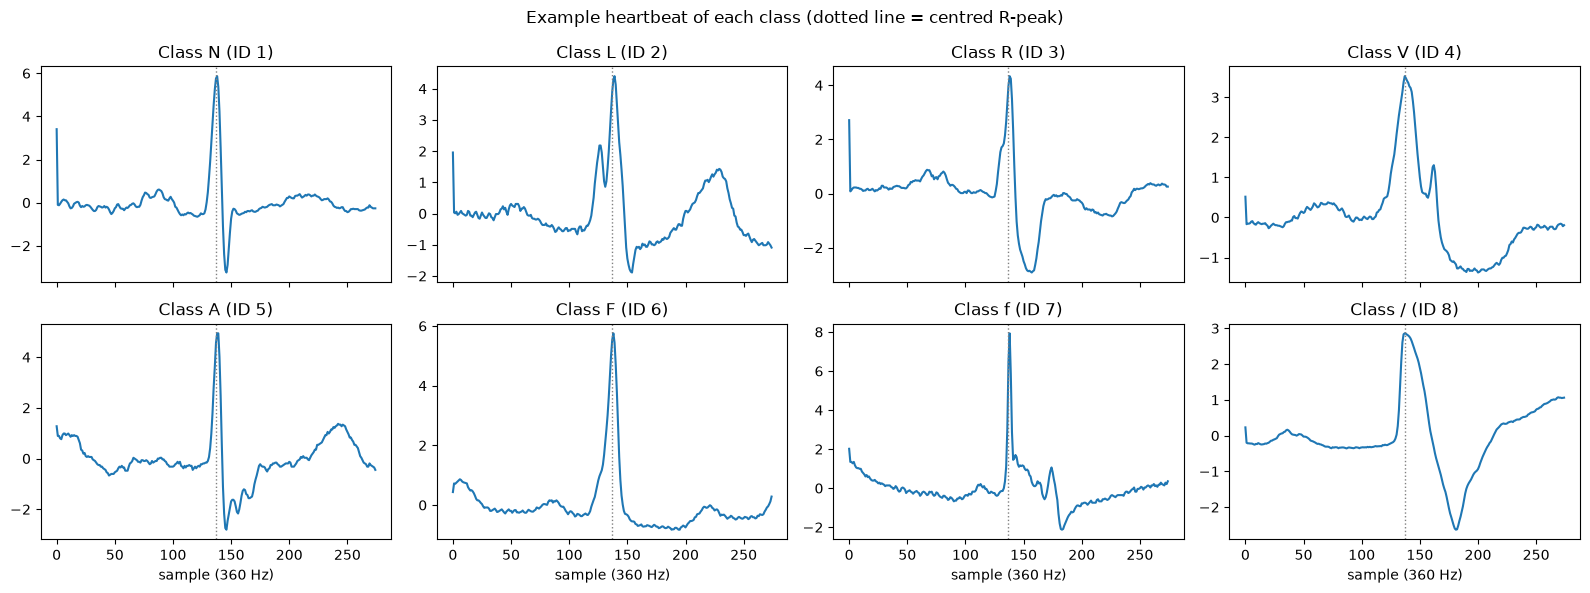

In [3]:
# One example beat per class (first one found in the beat hold-out training set)
fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True)
t = np.arange(Xb_train.shape[1])
for ax, cid, name in zip(axes.ravel(), CLASS_IDS, CLASS_NAMES):
    ax.plot(t, Xb_train[yb_train == cid][0])
    ax.axvline(137, color="grey", ls=":", lw=1)  # R-peak position
    ax.set_title(f"Class {name} (ID {cid})")
for ax in axes[-1]:
    ax.set_xlabel("sample (360 Hz)")
fig.suptitle("Example heartbeat of each class (dotted line = centred R-peak)")
fig.tight_layout()
fig.savefig(FIG_DIR / "example_beats_per_class.png", dpi=200)
plt.show()

In [4]:
# One-hot encoding of the labels (requirement 1). sklearn classifiers take the class IDs directly,
# but the one-hot version is what the PermFIT loss compares the predicted probabilities with.
Yb_train_onehot = one_hot(yb_train)
print("labels:", yb_train[:5])
print("one-hot:\n", Yb_train_onehot[:5].astype(int), "\ncolumns =", CLASS_NAMES)

labels: [7 2 6 8 1]
one-hot:
 [[0 0 0 0 0 0 1 0]
 [0 1 0 0 0 0 0 0]
 [0 0 0 0 0 1 0 0]
 [0 0 0 0 0 0 0 1]
 [1 0 0 0 0 0 0 0]] 
columns = ['N', 'L', 'R', 'V', 'A', 'F', 'f', '/']


## 2. Choosing the hyper-parameters

The test sets are **never** used for tuning. Instead a small grid search with 3-fold stratified cross-validation is run
on a 8,000-beat random subset of the beat hold-out training data (the full set would take too long for the SVM).
The same settings are then used for both splits, so the beat vs patient comparison is fair.

In [5]:
X_tune, _, y_tune, _ = train_test_split(Xb_train, yb_train, train_size=8000, stratify=yb_train, random_state=SEED)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

searches = {
    "SVM": GridSearchCV(SVC(kernel="rbf", gamma="scale"),
                        {"C": [1, 10, 100]}, cv=cv, scoring="f1_macro", n_jobs=-1),
    "Random Forest": GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=SEED),
                                  {"max_features": ["sqrt", 0.1], "min_samples_leaf": [1, 3]},
                                  cv=cv, scoring="f1_macro", n_jobs=-1),
}
best_params = {}
for name, search in searches.items():
    start = time.time()
    search.fit(X_tune, y_tune)
    best_params[name] = search.best_params_
    print(f"{name}: best {search.best_params_}  CV macro-F1 = {search.best_score_:.3f}  ({time.time() - start:.0f}s)")
    display(pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score"]])

SVM: best {'C': 100}  CV macro-F1 = 0.960  (4s)


,params,mean_test_score,std_test_score
0,{'C': 1},0.928039,0.002261
1,{'C': 10},0.955047,0.002543
2,{'C': 100},0.960181,0.001013


Random Forest: best {'max_features': 0.1, 'min_samples_leaf': 1}  CV macro-F1 = 0.954  (31s)


,params,mean_test_score,std_test_score
0,"{'max_features': 'sqrt', 'min_samples_leaf': 1}",0.953549,0.001479
1,"{'max_features': 'sqrt', 'min_samples_leaf': 3}",0.949535,0.004438
2,"{'max_features': 0.1, 'min_samples_leaf': 1}",0.954174,0.001016
3,"{'max_features': 0.1, 'min_samples_leaf': 3}",0.950166,0.002530


## 3. Train and evaluate both models on both splits

[SVM | beat hold-out] trained + predicted in 17s
=== SVM – beat hold-out ===
Accuracy: 0.9630

class precision  recall     f1  support
    N     0.997   0.958  0.977    28474
    L     0.981   0.998  0.989     1636
    R     0.992   0.992  0.992     2581
    V     0.799   0.959  0.872     1307
    A     0.533   0.920  0.674      783
    F     0.416   0.921  0.573      191
    f     0.897   0.938  0.917      416
    /     0.993   0.993  0.993     2054

Macro (over classes present): precision=0.826 recall=0.960 f1=0.873 | weighted f1=0.967


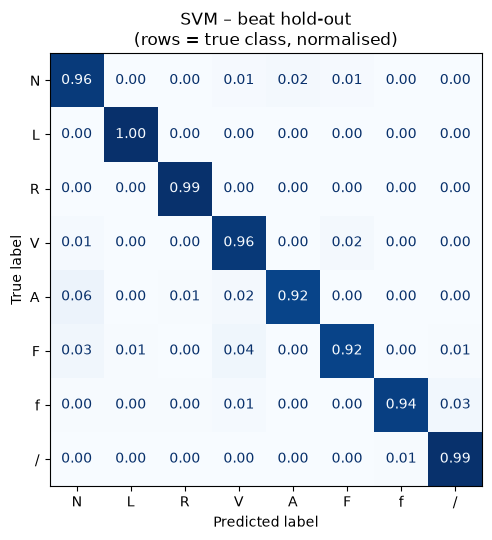

[SVM | patient hold-out] trained + predicted in 10s
=== SVM – patient hold-out ===
Accuracy: 0.8388

class precision  recall     f1  support
    N     0.942   0.888  0.914     9363
    L     0.000   0.000  0.000        0   (not in test set)
    R     0.000   0.000  0.000        0   (not in test set)
    V     0.823   0.979  0.894     1087
    A     0.000   0.000  0.000        0   (not in test set)
    F     0.585   0.292  0.390      387
    f     0.825   0.141  0.240     1138
    /     0.947   0.997  0.971     2507

Macro (over classes present): precision=0.824 recall=0.659 f1=0.682 | weighted f1=0.855


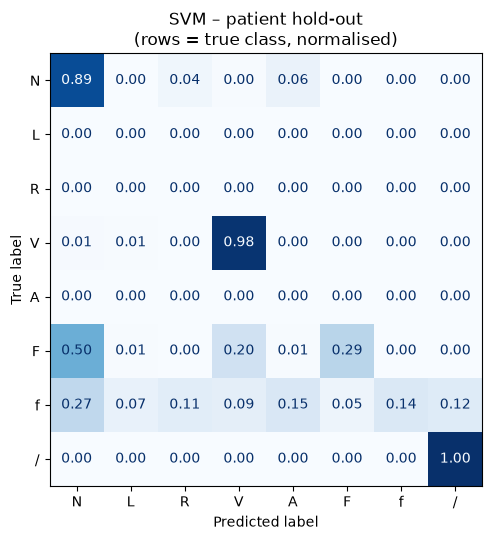

[Random Forest | beat hold-out] trained + predicted in 17s
=== Random Forest – beat hold-out ===
Accuracy: 0.9677

class precision  recall     f1  support
    N     0.996   0.965  0.980    28474
    L     0.979   0.999  0.989     1636
    R     0.991   0.990  0.991     2581
    V     0.740   0.964  0.837     1307
    A     0.631   0.899  0.741      783
    F     0.607   0.890  0.722      191
    f     0.862   0.930  0.895      416
    /     0.990   0.994  0.992     2054

Macro (over classes present): precision=0.850 recall=0.954 f1=0.893 | weighted f1=0.970


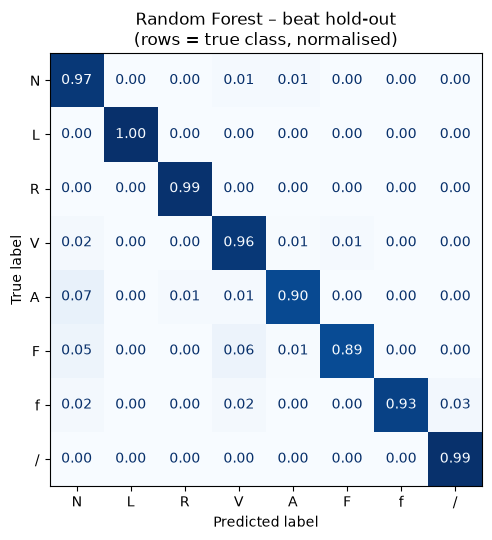

[Random Forest | patient hold-out] trained + predicted in 20s
=== Random Forest – patient hold-out ===
Accuracy: 0.8356

class precision  recall     f1  support
    N     0.943   0.910  0.926     9363
    L     0.000   0.000  0.000        0   (not in test set)
    R     0.000   0.000  0.000        0   (not in test set)
    V     0.626   0.990  0.767     1087
    A     0.000   0.000  0.000        0   (not in test set)
    F     0.500   0.003  0.005      387
    f     1.000   0.004  0.007     1138
    /     0.888   0.998  0.940     2507

Macro (over classes present): precision=0.791 recall=0.581 f1=0.529 | weighted f1=0.820


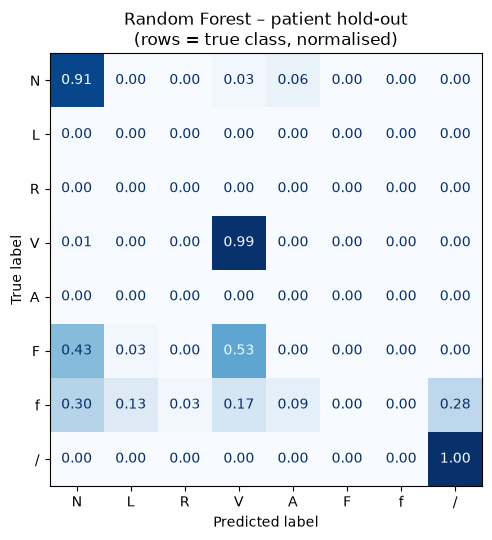

In [6]:
def make_model(name):
    if name == "SVM":
        return SVC(kernel="rbf", gamma="scale", random_state=SEED, **best_params["SVM"])
    return RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED, **best_params["Random Forest"])

splits = {"beat hold-out": (Xb_train, yb_train, Xb_test, yb_test),
          "patient hold-out": (Xp_train, yp_train, Xp_test, yp_test)}

results = []
for model_name in ["SVM", "Random Forest"]:
    for split_name, (X_tr, y_tr, X_te, y_te) in splits.items():
        model = make_model(model_name)
        start = time.time()
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_te)
        print(f"[{model_name} | {split_name}] trained + predicted in {time.time() - start:.0f}s")
        res = evaluate(y_te, y_pred, title=f"{model_name} – {split_name}",
                       save_as=f"cm_{model_name.replace(' ', '_').lower()}_{split_name.split()[0]}.png")
        res["split"] = split_name
        results.append(res)

## 4. Summary table

In [7]:
table = (pd.DataFrame(results)
         .assign(model=lambda d: d["model"].str.split(" – ").str[0])
         [["model", "split", "accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1"]]
         .round(3))
table.to_csv(DATA_DIR / "classification_results.csv", index=False)
table

,model,split,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,SVM,beat hold-out,0.963,0.826,0.960,0.873,0.967
1,SVM,patient hold-out,0.839,0.824,0.659,0.682,0.855
2,Random Forest,beat hold-out,0.968,0.850,0.954,0.893,0.970
3,Random Forest,patient hold-out,0.836,0.791,0.581,0.529,0.820


In [8]:
# How much does each model lose when tested on unseen patients? (= effect of data leakage in the beat split)
drop = table.pivot(index="model", columns="split", values="macro_f1")
drop["drop in macro-F1"] = drop["beat hold-out"] - drop["patient hold-out"]
drop.round(3)

split,beat hold-out,patient hold-out,drop in macro-F1
model,,,
Random Forest,0.893,0.529,0.364
SVM,0.873,0.682,0.191


**Reading the results (for the report):**

* *Beat hold-out* mixes beats of the same patient into training and test, so the model partly recognises the patient
  rather than the arrhythmia – the scores are optimistic.
* *Patient hold-out* is the realistic test: "does it work for a new person?". The drop between the two is the size of
  the data-leakage effect.
* For the patient split, macro scores only average the five classes present (N, V, F, f, /). Look at the confusion
  matrix rows to see which classes get confused – e.g. fusion beats (F) look like a mix of N and V.